# SET with UK-DALE

Compare dense and sparse models. Use `SET_RUN_MODE=full` for full training.


In [1]:
import os
from pathlib import Path
import time
import pickle
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.regularizers import Regularizer, l1, l2
import matplotlib.pyplot as plt

# Smoke mode runs every model/target on a small subset. Full mode uses the
# original sample split and 50 epochs (200 for SET DNN).
RUN_MODE = os.environ.get("SET_RUN_MODE", "smoke")
assert RUN_MODE in {"smoke", "full"}
EPOCHS = 1 if RUN_MODE == "smoke" else 50
SET_DNN_EPOCHS = 2 if RUN_MODE == "smoke" else 200
SET_EPOCHS = 2 if RUN_MODE == "smoke" else 50
keras.utils.set_random_seed(42)
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Mode:", RUN_MODE, "TensorFlow:", tf.__version__)


Matplotlib is building the font cache; this may take a moment.


Mode: smoke TensorFlow: 2.21.0


In [2]:
# Local files; set SET_DATA_DIR if the CSV files are stored elsewhere.
DATA_DIR = Path(os.environ.get("SET_DATA_DIR", str(Path.cwd())))
if not (DATA_DIR / "samX.csv").exists():
    DATA_DIR = Path.cwd().parent  # Set SET_DATA_DIR when data are elsewhere.


## Load data


In [3]:
# Both CSVs contain a header and a nonnumeric row-name column.
train = np.loadtxt(DATA_DIR / "samX.csv", delimiter=",", skiprows=1,
                   usecols=range(1, 601), dtype=np.float32)
label = np.loadtxt(DATA_DIR / "samY.csv", delimiter=",", skiprows=1,
                   usecols=range(1, 5), dtype=np.float32)
assert len(train) == len(label)
assert np.isfinite(train).all() and np.isfinite(label).all()
assert np.isin(label, [0, 1]).all()


In [4]:
train=np.array(train)
label=np.array(label)
train=train.astype('float32')
label=label.astype('float32')
print(train.shape)
print(label.shape)

(10000, 600)
(10000, 4)


In [5]:
train = train.reshape((len(train), train.shape[1], 1))
print(train.shape)


(10000, 600, 1)


In [6]:
# Preserve the original ordered split: first 2,000 held out.
trainx, trainy = train[2000:], label[2000:]
testx, testy = train[:2000], label[:2000]
if RUN_MODE == "smoke":
    trainx, trainy = trainx[:128], trainy[:128]
    testx, testy = testx[:64], testy[:64]
testylis = [testy[:, i:i+1] for i in range(4)]
print("Training:", trainx.shape, trainy.shape, "Test:", testx.shape, testy.shape)


Training: (128, 600, 1) (128, 4) Test: (64, 600, 1) (64, 4)


In [7]:
lbs = [trainy[:, i:i+1] for i in range(4)]


## Sparse functions


In [8]:
epsilon = 20
zeta = 0.3

@keras.utils.register_keras_serializable(package="SET")
class MaskWeights(keras.constraints.Constraint):
    def __init__(self, mask):
        self.mask = np.asarray(mask, dtype=np.float32)
    def __call__(self, w):
        return w * tf.cast(self.mask, w.dtype)
    def get_config(self):
        return {"mask": self.mask.tolist()}

def rewireMask(weights, noWeights):
    # Prune weights nearest zero separately by sign, then restore edge count.
    flat = weights.ravel()
    core = (flat != 0)
    for indices in (np.flatnonzero(flat < 0), np.flatnonzero(flat > 0)):
        count = int(zeta * len(indices))
        if count:
            removed = indices[np.argsort(np.abs(flat[indices]))[:count]]
            core[removed] = False
    mask = core.copy()
    count = int(noWeights) - int(mask.sum())
    assert 0 <= count <= int((~mask).sum())
    if count:
        mask[np.random.choice(np.flatnonzero(~mask), count, replace=False)] = True
    return mask.reshape(weights.shape).astype('float32'), core.reshape(weights.shape).astype('float32')

def createWeightsMask(epsilon, noRows, noCols):
    probability = min(1., epsilon * (noRows + noCols) / (noRows * noCols))
    mask = (np.random.random((noRows, noCols)) < probability).astype('float32')
    return int(mask.sum()), mask


## Train models


In [9]:
def count_neurons(model):
    return sum(int(np.count_nonzero(np.sum(np.abs(w[0]), axis=1) > 1e-3))
               for layer in model.layers
               if len(w := layer.get_weights()) and w[0].ndim == 2)

class TrainHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.losses = []
        self.neurons = [count_neurons(self.model)]
    def on_train_batch_end(self, batch, logs=None):
        self.losses.append((logs or {}).get('loss'))
        self.neurons.append(count_neurons(self.model))

@keras.utils.register_keras_serializable(package="SET")
class L21(Regularizer):
    def __init__(self, C=0.):
        self.C = float(C)
    def __call__(self, x):
        # Epsilon avoids undefined gradients for an all-zero row.
        return self.C * tf.sqrt(tf.cast(tf.shape(x)[1], x.dtype)) * tf.reduce_sum(
            tf.sqrt(tf.reduce_sum(tf.square(x), axis=1) + keras.backend.epsilon()))
    def get_config(self):
        return {'C': self.C}


In [10]:
# normal DNN model

def create_nonconv_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.BatchNormalization()(li)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid')(output)
  model=models.Model(inputs=li, outputs=output)
  return model

DNNmodel=[]
DNNmodel.append(create_nonconv_model(600))
DNNmodel.append(create_nonconv_model(600))
DNNmodel.append(create_nonconv_model(600))
DNNmodel.append(create_nonconv_model(600))
DNNhis=[]
start_time = time.time()
for i in range(4):

  DNNmodel[i].compile(optimizer='sgd',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  DNNhis.append(DNNmodel[i].fit(trainx,lbs[i],epochs=EPOCHS))
print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.4062 - loss: 0.3987 - mean_absolute_error: 0.5535 - precision: 0.5263 - recall: 0.5000

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4688 - loss: 0.3652 - mean_absolute_error: 0.5401 - precision: 0.5294 - recall: 0.5000  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.5625 - loss: 0.3491 - mean_absolute_error: 0.5015 - precision: 0.6667 - recall: 0.6000

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5234 - loss: 0.3314 - mean_absolute_error: 0.4935 - precision: 0.5946 - recall: 0.5867  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.5312 - loss: 0.3279 - mean_absolute_error: 0.5265 - precision: 0.4615 - recall: 0.4286

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5625 - loss: 0.3044 - mean_absolute_error: 0.4947 - precision: 0.4667 - recall: 0.5385  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.3125 - loss: 0.4481 - mean_absolute_error: 0.6116 - precision: 0.3636 - recall: 0.2105

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4531 - loss: 0.3443 - mean_absolute_error: 0.5195 - precision: 0.4490 - recall: 0.3385  


--- 0.5951290130615234 seconds ---


In [11]:
lambda_val = .7

# normal las DNN model

def create_nonconv_lasso_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.BatchNormalization()(li)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid',kernel_regularizer = l1(lambda_val))(output)
  model=models.Model(inputs=li, outputs=output)
  return model

DNNlasmodel=[]
DNNlasmodel.append(create_nonconv_lasso_model(600))
DNNlasmodel.append(create_nonconv_lasso_model(600))
DNNlasmodel.append(create_nonconv_lasso_model(600))
DNNlasmodel.append(create_nonconv_lasso_model(600))
DNNlashis=[]
start_time = time.time()
for i in range(4):

  DNNlasmodel[i].compile(optimizer='adam',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  DNNlashis.append(DNNlasmodel[i].fit(trainx,lbs[i],epochs=EPOCHS))

print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.4062 - loss: 9.5644 - mean_absolute_error: 0.5593 - precision: 0.5217 - recall: 0.6000

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5547 - loss: 9.3673 - mean_absolute_error: 0.4427 - precision: 0.6230 - recall: 0.5278  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step - accuracy: 0.4688 - loss: 8.7379 - mean_absolute_error: 0.4889 - precision: 0.6154 - recall: 0.4000

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6641 - loss: 8.5437 - mean_absolute_error: 0.3580 - precision: 0.7963 - recall: 0.5733  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.4062 - loss: 8.9157 - mean_absolute_error: 0.5553 - precision: 0.4000 - recall: 0.7143

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4688 - loss: 8.8024 - mean_absolute_error: 0.5239 - precision: 0.4048 - recall: 0.6538  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.4688 - loss: 8.5406 - mean_absolute_error: 0.5292 - precision: 0.5625 - recall: 0.4737

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5625 - loss: 8.3992 - mean_absolute_error: 0.4345 - precision: 0.5849 - recall: 0.4769  


--- 1.011728048324585 seconds ---


In [12]:

# normal group las DNN model

def create_nonconv_group_lasso_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.BatchNormalization()(li)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid',kernel_regularizer=L21(0.001))(output)
  model=models.Model(inputs=li, outputs=output)
  return model

DNNgrouplasmodel=[]
DNNgrouplasmodel.append(create_nonconv_group_lasso_model(600))
DNNgrouplasmodel.append(create_nonconv_group_lasso_model(600))
DNNgrouplasmodel.append(create_nonconv_group_lasso_model(600))
DNNgrouplasmodel.append(create_nonconv_group_lasso_model(600))
DNNgrouplashis=[]
nehis=[]
start_time = time.time()
for i in range(4):

  DNNgrouplasmodel[i].compile(optimizer='adam',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  DNNgrouplashis.append(DNNgrouplasmodel[i].fit(trainx,lbs[i],epochs=EPOCHS))
  nehis.append(TrainHistory())

print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.4688 - loss: 0.3945 - mean_absolute_error: 0.5324 - precision: 0.5789 - recall: 0.5500

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5625 - loss: 0.3318 - mean_absolute_error: 0.4462 - precision: 0.6379 - recall: 0.5139  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 281ms/step - accuracy: 0.4375 - loss: 0.3832 - mean_absolute_error: 0.5074 - precision: 0.5556 - recall: 0.5000

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6484 - loss: 0.2638 - mean_absolute_error: 0.3411 - precision: 0.7419 - recall: 0.6133  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - accuracy: 0.5625 - loss: 0.3152 - mean_absolute_error: 0.4737 - precision: 0.5000 - recall: 0.6429

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5078 - loss: 0.3849 - mean_absolute_error: 0.5166 - precision: 0.4247 - recall: 0.5962  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.6562 - loss: 0.2459 - mean_absolute_error: 0.4147 - precision: 0.7500 - recall: 0.6316

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6562 - loss: 0.2761 - mean_absolute_error: 0.3959 - precision: 0.6780 - recall: 0.6154  


--- 1.049401044845581 seconds ---


In [13]:
# SET DNN
def weightsEvolution(model):
# this represents the core of the SET procedure. It removes the weights closest to zero in each layer and add new random weights

    bat=model.get_layer("bat_layer").get_weights()
    w2=model.get_layer("dense_layer2").get_weights()
    w1 = model.get_layer("dense_layer1").get_weights()
    
    [wm1, wm1Core] = rewireMask(w1[0], noPar1)

    w1[0] = w1[0] * wm1Core
    return bat,w1,w2,wm1

def create_SET_nonconv_model(windowsize,bat,w1,w2,wm1):
  li=layers.Input((windowsize,1))
  x=layers.BatchNormalization(name='bat_layer')(li)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100,name='dense_layer1',kernel_constraint=MaskWeights(wm1))(x)
  output=layers.Dense(1,activation='sigmoid',name='dense_layer2')(output)
  model=models.Model(inputs=li, outputs=output)
  for layer_name, initial in [("conv_layer1", locals().get("lconv1")),
                              ("conv_layer2", locals().get("lconv2")),
                              ("bat_layer", locals().get("bat")),
                              ("dense_layer1", locals().get("w1")),
                              ("dense_layer2", locals().get("w2"))]:
    if initial is not None:
      model.get_layer(layer_name).set_weights(initial)
  if "wm1" in locals():
    sparse = model.get_layer("dense_layer1")
    kernel, bias = sparse.get_weights()
    sparse.set_weights([kernel * wm1, bias])
  return model


SETDNNmodel=[]
SETDNNhis=[]
start_time = time.time()
for i in range(4):
  SETDNNhis.append({})
  [noPar1, wm1] = createWeightsMask(epsilon,600,100)
  w1=None
  w2=None
  bat=None
  SETDNNmodel.append(create_SET_nonconv_model(600,bat,w1,w2,wm1))
  for j in range(SET_DNN_EPOCHS):

    SETDNNmodel[i].compile(loss='mean_squared_error', optimizer='sgd', metrics=['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
    historytemp = SETDNNmodel[i].fit(trainx,lbs[i],epochs=1)
    for key in historytemp.history:
      
      if key in SETDNNhis[i]:
        SETDNNhis[i][key].append(historytemp.history[key])
      else:
        SETDNNhis[i][key]=[historytemp.history[key]]
    if j + 1 < SET_DNN_EPOCHS:
      bat,w1,w2,wm1=weightsEvolution(SETDNNmodel[i])
      keras.backend.clear_session()
      
      SETDNNmodel[i]=create_SET_nonconv_model(600,bat,w1,w2,wm1)
  
    

print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.5312 - loss: 0.2720 - mean_absolute_error: 0.4938 - precision: 0.6667 - recall: 0.5000

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4141 - loss: 0.3042 - mean_absolute_error: 0.5217 - precision: 0.4754 - recall: 0.4028  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.5312 - loss: 0.2675 - mean_absolute_error: 0.4834 - precision: 0.6923 - recall: 0.4500

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4688 - loss: 0.2789 - mean_absolute_error: 0.4973 - precision: 0.5357 - recall: 0.4167  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.4375 - loss: 0.3875 - mean_absolute_error: 0.5698 - precision: 0.5714 - recall: 0.4000

...

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.5312 - loss: 0.2655 - mean_absolute_error: 0.4980 - precision: 0.6429 - recall: 0.4737

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4844 - loss: 0.2594 - mean_absolute_error: 0.4916 - precision: 0.4930 - recall: 0.5385  


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.4688 - loss: 0.2784 - mean_absolute_error: 0.5112 - precision: 0.6000 - recall: 0.3158

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5547 - loss: 0.2588 - mean_absolute_error: 0.4897 - precision: 0.5833 - recall: 0.4308  


--- 1.4325230121612549 seconds ---


In [14]:
#normal 1d CONV 
def create_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu')(li)
  x=layers.Conv1D(64, 2, activation='relu')(x)
  x=layers.BatchNormalization()(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid')(output)
  model=models.Model(inputs=li, outputs=output)
  return model

class TestCallback(keras.callbacks.Callback):
  def __init__(self, test_data):
      self.test_data = test_data
  def on_epoch_end(self, epoch, logs=None):
      x, y = self.test_data
      print(x.shape)
      print(y.shape)
      self.test_time = time.time()
      result = self.model.evaluate(x, y, verbose=1)
      testt=time.time() - self.test_time
      print('\nTesting loss: {}, acc: {}\n'.format(result[0], result[1]))
      print('\nTesting time: {}'.format(testt))
tmodel=[]
tmodel.append(create_model(600))
tmodel.append(create_model(600))
tmodel.append(create_model(600))
tmodel.append(create_model(600))
CONVhis=[]
start_time = time.time()
for i in range(4):

  tmodel[i].compile(optimizer='sgd',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  CONVhis.append(tmodel[i].fit(trainx,lbs[i],epochs=EPOCHS,callbacks=[TestCallback((testx, testylis[i]))]))

print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.5938 - loss: 0.2773 - mean_absolute_error: 0.4368 - precision: 0.6842 - recall: 0.6500

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6250 - loss: 0.3412 - mean_absolute_error: 0.3747 - precision: 0.5862 - recall: 1.0000

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6250 - loss: 0.3629 - mean_absolute_error: 0.4000 - precision: 0.5789 - recall: 1.0000 



Testing loss: 0.36287444829940796, acc: 0.625


Testing time: 0.0676720142364502
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5938 - loss: 0.3072 - mean_absolute_error: 0.4044 - precision: 0.6667 - recall: 0.5556 


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.5938 - loss: 0.2786 - mean_absolute_error: 0.4196 - precision: 0.7059 - recall: 0.6000

...

(64, 600, 1)
(64, 1)


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.5000 - loss: 0.4497 - mean_absolute_error: 0.4940 - precision: 0.4643 - recall: 0.9286

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5156 - loss: 0.4491 - mean_absolute_error: 0.4917 - precision: 0.4630 - recall: 0.9259 



Testing loss: 0.4491238594055176, acc: 0.515625


Testing time: 0.06539702415466309
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6484 - loss: 0.2650 - mean_absolute_error: 0.3961 - precision: 0.6613 - recall: 0.6308 


--- 1.0387208461761475 seconds ---


In [15]:
#lasso 1d CONV 
lambda_val=0.7
def create_conv_lasso_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu')(li)
  x=layers.Conv1D(64, 2, activation='relu')(x)
  x=layers.BatchNormalization()(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid',kernel_regularizer = l1(lambda_val))(output)
  model=models.Model(inputs=li, outputs=output)
  return model


tlasmodel=[]
tlasmodel.append(create_conv_lasso_model(600))
tlasmodel.append(create_conv_lasso_model(600))
tlasmodel.append(create_conv_lasso_model(600))
tlasmodel.append(create_conv_lasso_model(600))
CONVlashis=[]
start_time = time.time()
for i in range(4):

  tlasmodel[i].compile(optimizer='adam',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  CONVlashis.append(tlasmodel[i].fit(trainx,lbs[i],epochs=EPOCHS,callbacks=[TestCallback((testx, testylis[i]))]))

print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 339ms/step - accuracy: 0.5312 - loss: 8.1993 - mean_absolute_error: 0.4934 - precision: 0.6923 - recall: 0.4500

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.5938 - loss: 8.0120 - mean_absolute_error: 0.4063 - precision: 0.5667 - recall: 1.0000

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5938 - loss: 8.0120 - mean_absolute_error: 0.4063 - precision: 0.5593 - recall: 1.0000 



Testing loss: 8.012031555175781, acc: 0.59375


Testing time: 0.0683143138885498
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6641 - loss: 8.0799 - mean_absolute_error: 0.3507 - precision: 0.7302 - recall: 0.6389 


1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 356ms/step - accuracy: 0.5000 - loss: 8.9460 - mean_absolute_error: 0.5168 - precision: 0.6250 - recall: 0.5000

...

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 334ms/step - accuracy: 0.4375 - loss: 8.8036 - mean_absolute_error: 0.5397 - precision: 0.5263 - recall: 0.5263

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5000 - loss: 8.6147 - mean_absolute_error: 0.5000 - precision: 0.4667 - recall: 1.0000

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5156 - loss: 8.5906 - mean_absolute_error: 0.4796 - precision: 0.4643 - recall: 0.9630 



Testing loss: 8.59062385559082, acc: 0.515625


Testing time: 0.06686520576477051
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6094 - loss: 8.6320 - mean_absolute_error: 0.3832 - precision: 0.6056 - recall: 0.6615 


--- 1.8743069171905518 seconds ---


In [16]:
#group lasso 1d CONV 
l21v=0.002
def create_conv_lasso_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu')(li)
  x=layers.Conv1D(64, 2, activation='relu')(x)
  x=layers.BatchNormalization()(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(20,activation='sigmoid',kernel_regularizer=L21(0.002))(output)
  output=layers.Dense(15,activation='sigmoid',kernel_regularizer=L21(0.002))(output)
  output=layers.Dense(1,activation='sigmoid',kernel_regularizer=L21(0.002))(output)
  model=models.Model(inputs=li, outputs=output)
  return model


cnngrouplasmodel=[]
cnngrouplasmodel.append(create_conv_lasso_model(600))
cnngrouplasmodel.append(create_conv_lasso_model(600))
cnngrouplasmodel.append(create_conv_lasso_model(600))
cnngrouplasmodel.append(create_conv_lasso_model(600))
CONVgrouplashis=[]
start_time = time.time()
for i in range(4):

  cnngrouplasmodel[i].compile(optimizer='adam',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  CONVgrouplashis.append(cnngrouplasmodel[i].fit(trainx,lbs[i],epochs=EPOCHS,callbacks=[TestCallback((testx, testylis[i]))]))

print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 442ms/step - accuracy: 0.6250 - loss: 0.9052 - mean_absolute_error: 0.4634 - precision: 0.6250 - recall: 1.0000

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5312 - loss: 0.9234 - mean_absolute_error: 0.4609 - precision: 0.5312 - recall: 1.0000

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5156 - loss: 0.9294 - mean_absolute_error: 0.4674 - precision: 0.5156 - recall: 1.0000 



Testing loss: 0.9294173717498779, acc: 0.515625


Testing time: 0.07848882675170898
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.5703 - loss: 0.8865 - mean_absolute_error: 0.4459 - precision: 0.5680 - recall: 0.9861 


1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 436ms/step - accuracy: 0.3750 - loss: 0.9593 - mean_absolute_error: 0.5272 - precision: 0.0000e+00 - recall: 0.0000e+00

...

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 438ms/step - accuracy: 0.5938 - loss: 0.9046 - mean_absolute_error: 0.4830 - precision: 0.5938 - recall: 1.0000

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.4688 - loss: 0.9517 - mean_absolute_error: 0.5124 - precision: 0.4516 - recall: 1.0000

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4844 - loss: 0.9476 - mean_absolute_error: 0.5087 - precision: 0.4500 - recall: 1.0000 



Testing loss: 0.9475668668746948, acc: 0.484375


Testing time: 0.07825994491577148
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6641 - loss: 0.8840 - mean_absolute_error: 0.4585 - precision: 0.6170 - recall: 0.8923 


--- 2.199876070022583 seconds ---


In [17]:
# All models below use the same training/test split.


In [18]:
#SET CONV CNN
class TimeHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, batch, logs=None):
        self.epoch_time_start = time.time()

    def on_epoch_end(self, batch, logs=None):
        self.times.append(time.time() - self.epoch_time_start)
import gc
def weightsEvolution(model):
        # this represents the core of the SET procedure. It removes the weights closest to zero in each layer and add new random weights
    lconv1=model.get_layer("conv_layer1").get_weights()
    lconv2=model.get_layer("conv_layer2").get_weights()
    bat=model.get_layer("bat_layer").get_weights()
    w2=model.get_layer("dense_layer2").get_weights()
    w1 = model.get_layer("dense_layer1").get_weights()
    
    [wm1, wm1Core] = rewireMask(w1[0], noPar1)

    w1[0] = w1[0] * wm1Core
    return lconv1,lconv2,bat,w1,w2,wm1

def create_SET_conv_model(windowsize,lconv1,lconv2,bat,w1,w2,wm1):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu',name='conv_layer1')(li)
  x=layers.Conv1D(64, 2, activation='relu',name='conv_layer2')(x)
  x=layers.BatchNormalization(name='bat_layer')(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100,name='dense_layer1',kernel_constraint=MaskWeights(wm1))(x)
  output=layers.Dense(1,activation='sigmoid',name='dense_layer2')(output)
  model=models.Model(inputs=li, outputs=output)
  for layer_name, initial in [("conv_layer1", locals().get("lconv1")),
                              ("conv_layer2", locals().get("lconv2")),
                              ("bat_layer", locals().get("bat")),
                              ("dense_layer1", locals().get("w1")),
                              ("dense_layer2", locals().get("w2"))]:
    if initial is not None:
      model.get_layer(layer_name).set_weights(initial)
  if "wm1" in locals():
    sparse = model.get_layer("dense_layer1")
    kernel, bias = sparse.get_weights()
    sparse.set_weights([kernel * wm1, bias])
  return model

SETCONVmodel=[]
SETCONVhis=[]

for i in range(4):
  SETCONVhis.append({})
  [noPar1, wm1] = createWeightsMask(epsilon,19136,100)
  lconv1=None
  lconv2=None
  w1=None
  w2=None
  bat=None
  SETCONVmodel.append(create_SET_conv_model(600,lconv1,lconv2,bat,w1,w2,wm1))
  for j in range(SET_EPOCHS):
    time_callback = TimeHistory()
    
    SETCONVmodel[i].compile(loss='mean_squared_error', optimizer='sgd', metrics=['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
    start_time = time.time()
    historytemp = SETCONVmodel[i].fit(trainx,lbs[i],epochs=1,callbacks=[TestCallback((testx, testylis[i])),time_callback])
    end_time = time.time()
    times = time_callback.times
    print("--- THE REAL %s seconds ---" % (times))
    for key in historytemp.history:
      
      if key in SETCONVhis[i]:
        SETCONVhis[i][key].append(historytemp.history[key])
      else:
        SETCONVhis[i][key]=[historytemp.history[key]]
    if j + 1 < SET_EPOCHS:
      lconv1,lconv2,bat,w1,w2,wm1=weightsEvolution(SETCONVmodel[i])
      keras.backend.clear_session()
      gc.collect()
  
      SETCONVmodel[i]=create_SET_conv_model(600,lconv1,lconv2,bat,w1,w2,wm1)

print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.3750 - loss: 0.3423 - mean_absolute_error: 0.5445 - precision: 0.5000 - recall: 0.2500

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.5938 - loss: 0.3413 - mean_absolute_error: 0.3937 - precision: 0.5667 - recall: 1.0000

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6094 - loss: 0.3656 - mean_absolute_error: 0.4164 - precision: 0.5690 - recall: 1.0000  



Testing loss: 0.36555716395378113, acc: 0.609375


Testing time: 0.17496609687805176
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5781 - loss: 0.2620 - mean_absolute_error: 0.4475 - precision: 0.6552 - recall: 0.5278 


--- THE REAL [0.4007589817047119] seconds ---


...

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.7500 - loss: 0.1749 - mean_absolute_error: 0.3468 - precision: 0.8235 - recall: 0.7368

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.4688 - loss: 0.4055 - mean_absolute_error: 0.4790 - precision: 0.4483 - recall: 0.9286

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5000 - loss: 0.4094 - mean_absolute_error: 0.4777 - precision: 0.4561 - recall: 0.9630 



Testing loss: 0.4093557596206665, acc: 0.5


Testing time: 0.06498384475708008
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7812 - loss: 0.1675 - mean_absolute_error: 0.3387 - precision: 0.7681 - recall: 0.8154 


--- THE REAL [0.27335500717163086] seconds ---
--- 0.2817540168762207 seconds ---


In [19]:
#temp SET lasso CONV CNN
class TimeHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, batch, logs=None):
        self.epoch_time_start = time.time()

    def on_epoch_end(self, batch, logs=None):
        self.times.append(time.time() - self.epoch_time_start)
import gc
def weightsEvolution(model):
        # this represents the core of the SET procedure. It removes the weights closest to zero in each layer and add new random weights
    lconv1=model.get_layer("conv_layer1").get_weights()
    lconv2=model.get_layer("conv_layer2").get_weights()
    bat=model.get_layer("bat_layer").get_weights()
    w2=model.get_layer("dense_layer2").get_weights()
    w1 = model.get_layer("dense_layer1").get_weights()
    
    [wm1, wm1Core] = rewireMask(w1[0], noPar1)

    w1[0] = w1[0] * wm1Core
    return lconv1,lconv2,bat,w1,w2,wm1
lambda_val=0.7
def create_SET_lasso_conv_model(windowsize,lconv1,lconv2,bat,w1,w2,wm1):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu',name='conv_layer1')(li)
  x=layers.Conv1D(64, 2, activation='relu',name='conv_layer2')(x)
  x=layers.BatchNormalization(name='bat_layer')(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100,name='dense_layer1',kernel_constraint=MaskWeights(wm1))(x)
  output=layers.Dense(1,activation='sigmoid',name='dense_layer2',kernel_regularizer = l1(lambda_val))(output)
  model=models.Model(inputs=li, outputs=output)
  for layer_name, initial in [("conv_layer1", locals().get("lconv1")),
                              ("conv_layer2", locals().get("lconv2")),
                              ("bat_layer", locals().get("bat")),
                              ("dense_layer1", locals().get("w1")),
                              ("dense_layer2", locals().get("w2"))]:
    if initial is not None:
      model.get_layer(layer_name).set_weights(initial)
  if "wm1" in locals():
    sparse = model.get_layer("dense_layer1")
    kernel, bias = sparse.get_weights()
    sparse.set_weights([kernel * wm1, bias])
  return model

SETLASSOCONVmodel=[]
SETLASSOCONVhis=[]

for i in range(4):
  SETLASSOCONVhis.append({})
  [noPar1, wm1] = createWeightsMask(epsilon,19136,100)
  lconv1=None
  lconv2=None
  w1=None
  w2=None
  bat=None
  SETLASSOCONVmodel.append(create_SET_lasso_conv_model(600,lconv1,lconv2,bat,w1,w2,wm1))
  for j in range(SET_EPOCHS):
    time_callback = TimeHistory()
    
    SETLASSOCONVmodel[i].compile(loss='mean_squared_error', optimizer='adam', metrics=['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
    start_time = time.time()
    historytemp = SETLASSOCONVmodel[i].fit(trainx,lbs[i],epochs=1,callbacks=[TestCallback((testx, testylis[i])),time_callback])
    end_time = time.time()
    times = time_callback.times
    print("--- THE REAL %s seconds ---" % (times))
    for key in historytemp.history:
      
      if key in SETLASSOCONVhis[i]:
        SETLASSOCONVhis[i][key].append(historytemp.history[key])
      else:
        SETLASSOCONVhis[i][key]=[historytemp.history[key]]
    if j + 1 < SET_EPOCHS:
      lconv1,lconv2,bat,w1,w2,wm1=weightsEvolution(SETLASSOCONVmodel[i])
      keras.backend.clear_session()
      gc.collect()
  
      SETLASSOCONVmodel[i]=create_SET_lasso_conv_model(600,lconv1,lconv2,bat,w1,w2,wm1)

print("--- %s seconds ---" % (time.time() - start_time))

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 403ms/step - accuracy: 0.5000 - loss: 8.9486 - mean_absolute_error: 0.4917 - precision: 0.6429 - recall: 0.4500

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6562 - loss: 8.7256 - mean_absolute_error: 0.3670 - precision: 0.6071 - recall: 1.0000

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6406 - loss: 8.7420 - mean_absolute_error: 0.3794 - precision: 0.5893 - recall: 1.0000 



Testing loss: 8.741954803466797, acc: 0.640625


Testing time: 0.06768584251403809
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6016 - loss: 8.8700 - mean_absolute_error: 0.3982 - precision: 0.6909 - recall: 0.5278 


--- THE REAL [0.49548959732055664] seconds ---


...

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 362ms/step - accuracy: 0.7500 - loss: 8.5304 - mean_absolute_error: 0.2364 - precision: 0.7619 - recall: 0.8421

(64, 600, 1)
(64, 1)
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5312 - loss: 8.4693 - mean_absolute_error: 0.4555 - precision: 0.4815 - recall: 0.9286

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5938 - loss: 8.4263 - mean_absolute_error: 0.4047 - precision: 0.5098 - recall: 0.9630 



Testing loss: 8.426290512084961, acc: 0.59375


Testing time: 0.06687307357788086
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7422 - loss: 8.4488 - mean_absolute_error: 0.2623 - precision: 0.7162 - recall: 0.8154 


--- THE REAL [0.45363616943359375] seconds ---
--- 0.46169233322143555 seconds ---


In [20]:
# Flatten the legacy SET history representation for consistent plotting/export.
for collection in (SETDNNhis, SETCONVhis, SETLASSOCONVhis):
    for history in collection:
        for key, values in history.items():
            history[key] = np.asarray(values).reshape(-1).tolist()
dh = [h.history for h in DNNhis]
sdh = SETDNNhis
ch = [h.history for h in CONVhis]
sch = SETCONVhis


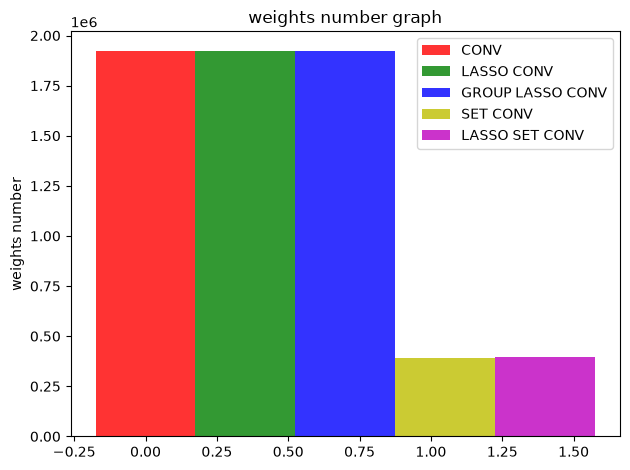

In [21]:
bar_width = 0.35
opacity = 0.8
a2,b=createWeightsMask(epsilon,19136,100)
index = np.arange(4)

fig, ax = plt.subplots()

def countWeight(model):
  weight_count=[]
  for var in model.trainable_variables:
    weight_count.append(tf.math.count_nonzero(var))
  return np.sum(weight_count)


conv_weight=countWeight(tmodel[0])
las_conv_weight=countWeight(tlasmodel[0])
group_conv_weight=countWeight(cnngrouplasmodel[0])
set_conv_weight=countWeight(SETCONVmodel[0])
set_LASSO_conv_weight=countWeight(SETLASSOCONVmodel[0])

rects1 = plt.bar(0, conv_weight, bar_width,
alpha=opacity,
color='red',
label='CONV')

rects2 = plt.bar(bar_width, las_conv_weight, bar_width,
alpha=opacity,
color='g',
label='LASSO CONV')


rects3 = plt.bar(bar_width*2, group_conv_weight, bar_width,
alpha=opacity,
color='b',
label='GROUP LASSO CONV')

rects4 = plt.bar(bar_width*3, set_conv_weight, bar_width,
alpha=opacity,
color='y',
label='SET CONV')

rects4 = plt.bar(bar_width*4, set_LASSO_conv_weight, bar_width,
alpha=opacity,
color='m',
label='LASSO SET CONV')

plt.ylabel('weights number')
plt.title('weights number graph')
#plt.xticks(index + bar_width, ('washing machine', 'dish washer', 'fridage', 'micromwave'))
plt.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / ('conv_weights.png'), dpi=150)
plt.show(); plt.close()

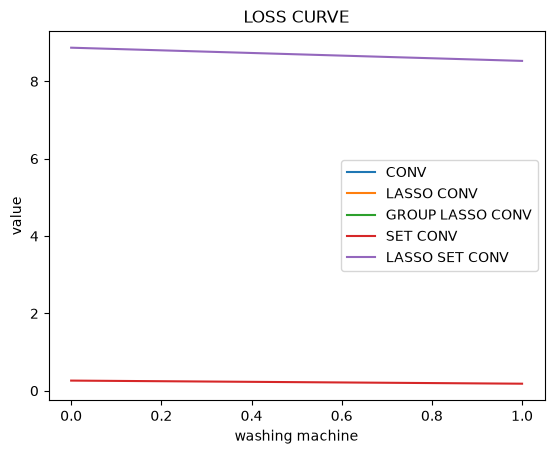

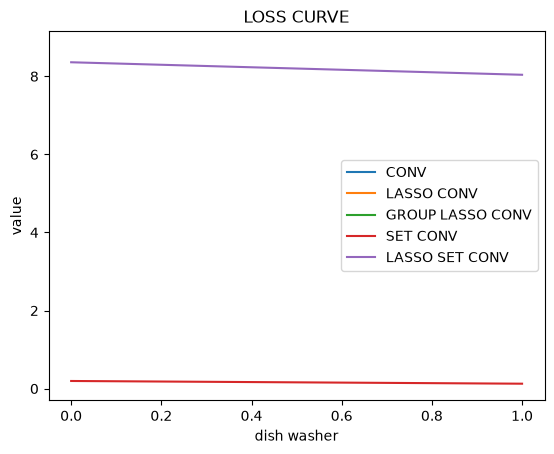

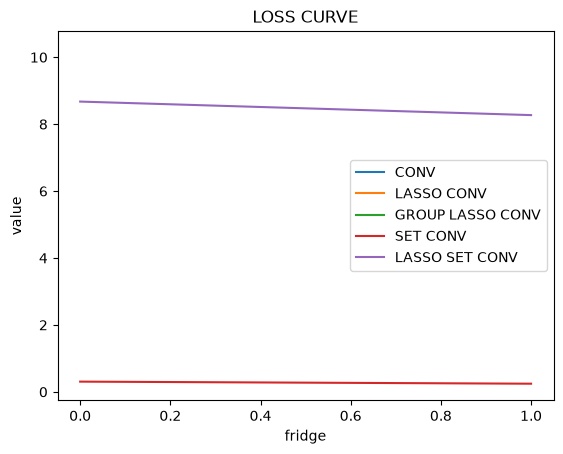

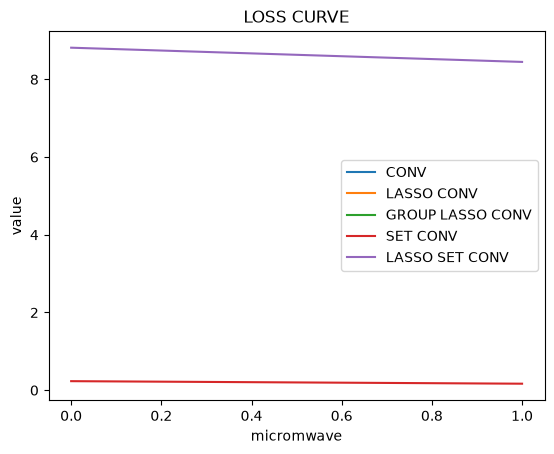

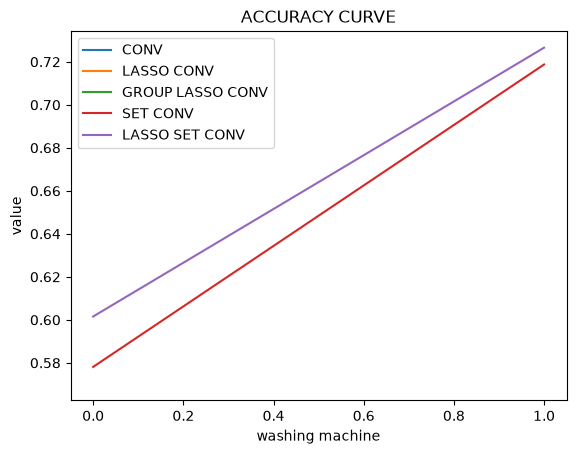

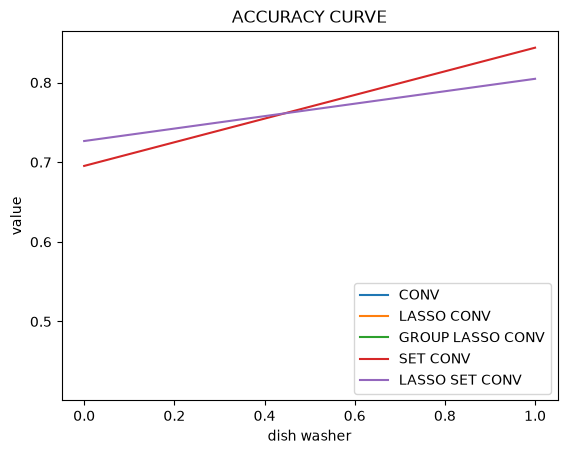

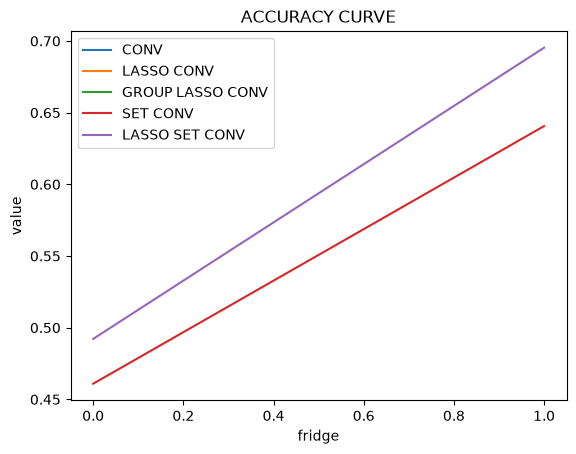

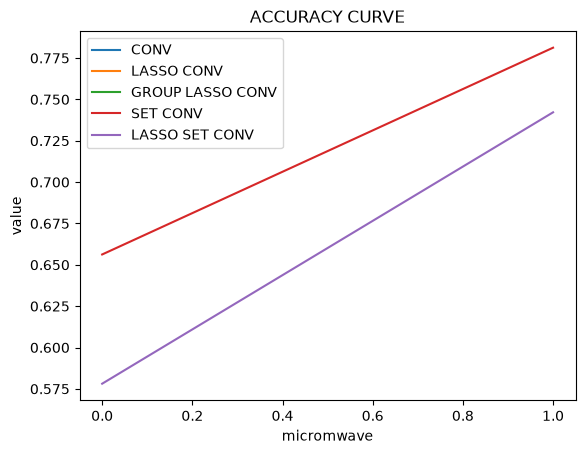

In [22]:
gn=['loss','accuracy']
device=['washing machine', 'dish washer', 'fridge', 'micromwave']

for i in range(2):
  for j in range(4):
    index=range(len(CONVhis[j].history[gn[i]]))
    plt.plot(range(len(CONVhis[j].history[gn[i]])),CONVhis[j].history[gn[i]],label='CONV')
    plt.plot(range(len(CONVlashis[j].history[gn[i]])),CONVlashis[j].history[gn[i]], label='LASSO CONV')
    plt.plot(range(len(CONVgrouplashis[j].history[gn[i]])),CONVgrouplashis[j].history[gn[i]],label='GROUP LASSO CONV')
    plt.plot(range(len(SETCONVhis[j][gn[i]])),SETCONVhis[j][gn[i]],label='SET CONV')
    plt.plot(range(len(SETLASSOCONVhis[j][gn[i]])),SETLASSOCONVhis[j][gn[i]],label='LASSO SET CONV')
    plt.xlabel(device[j])
    plt.ylabel('value')
    plt.title(gn[i].upper()+' CURVE')
    plt.legend();
    plt.savefig(OUTPUT_DIR / ('conv_' + device[j]+' '+gn[i]+' curve'+'.png'), dpi=150)
    plt.show(); plt.close()

## Plot results


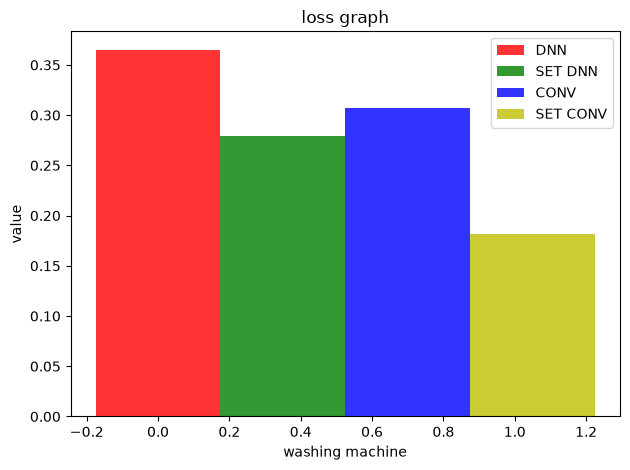

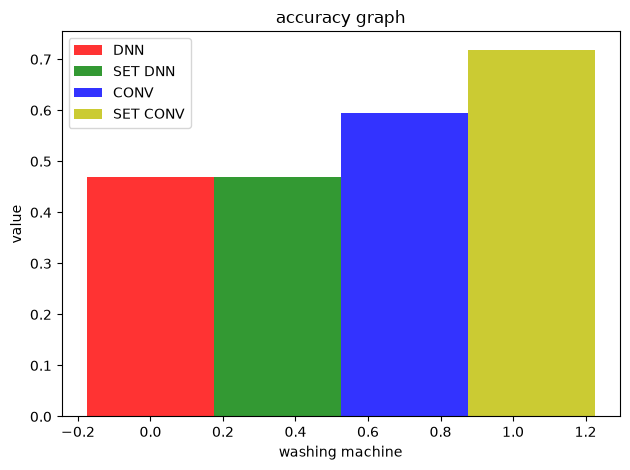

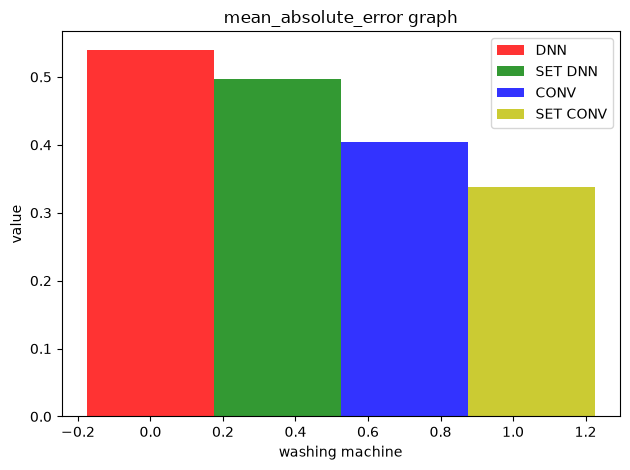

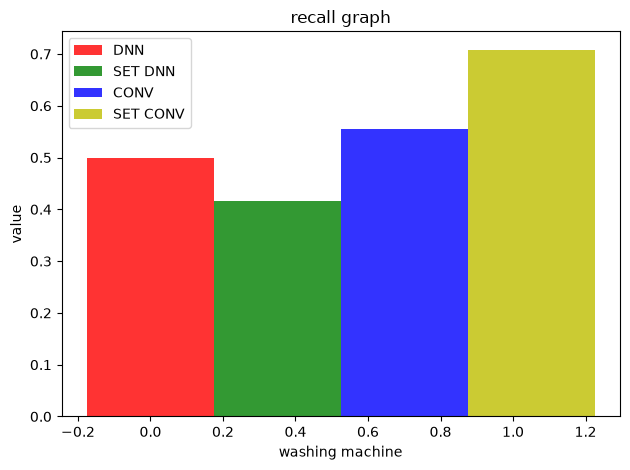

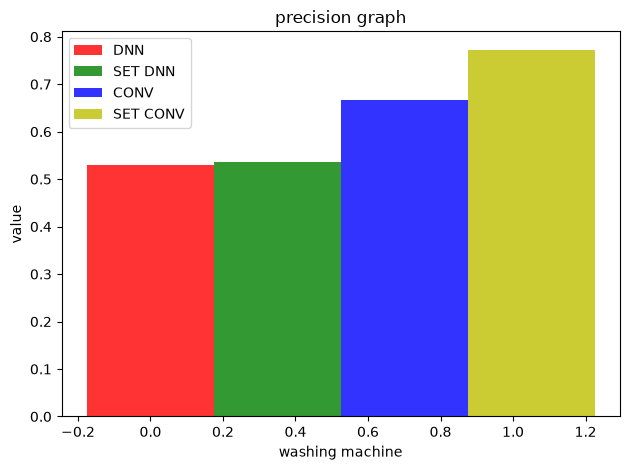

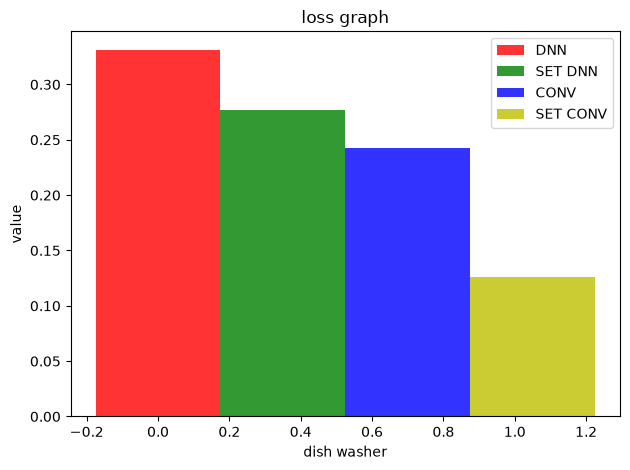

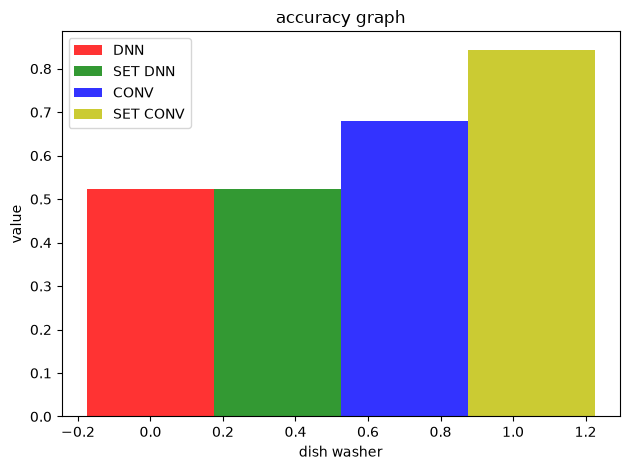

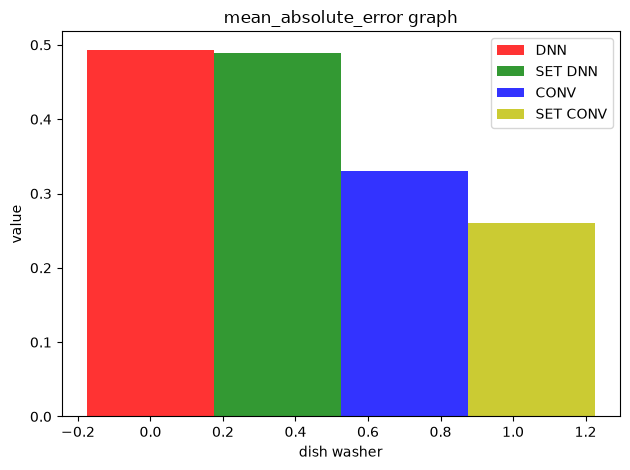

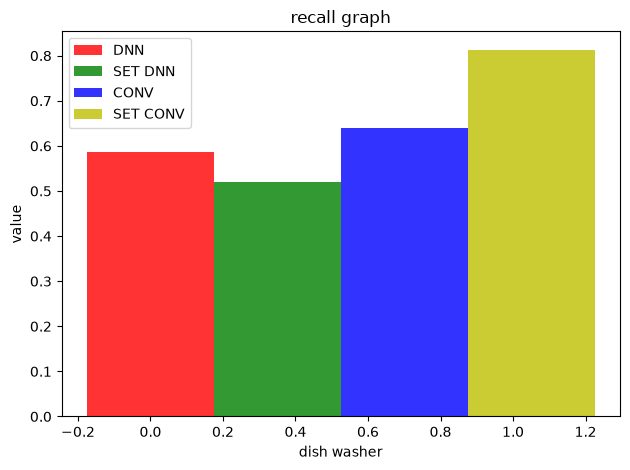

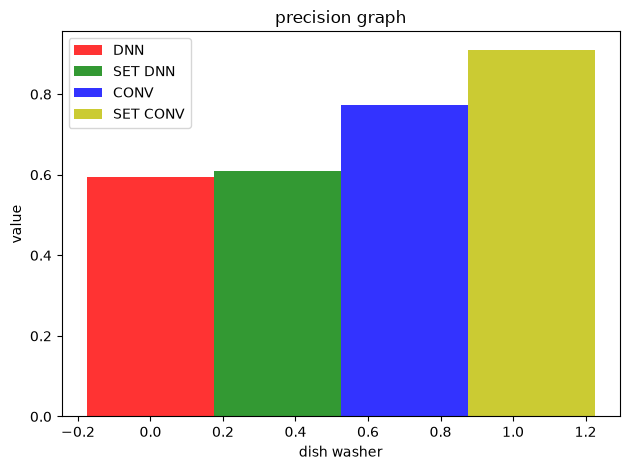

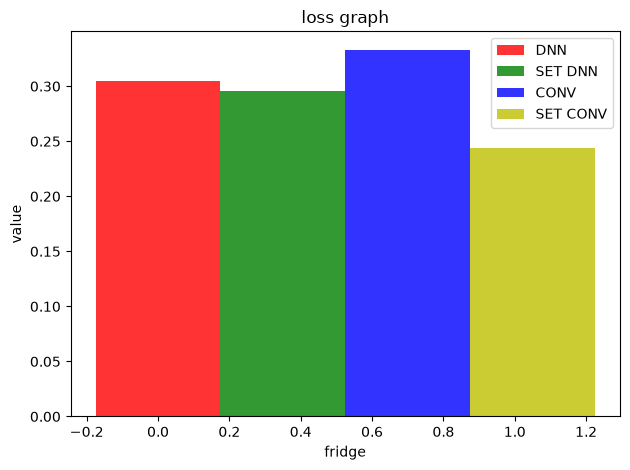

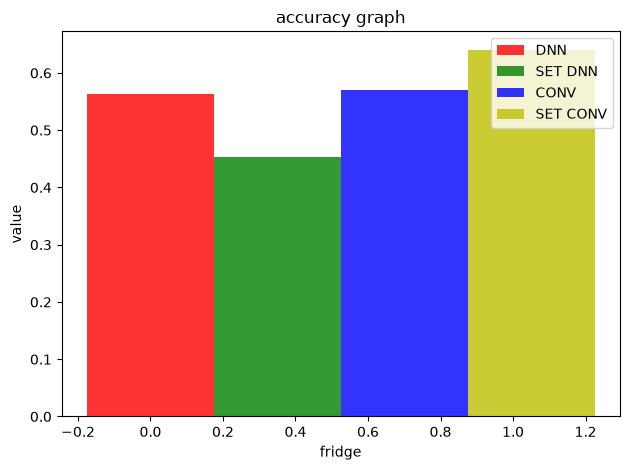

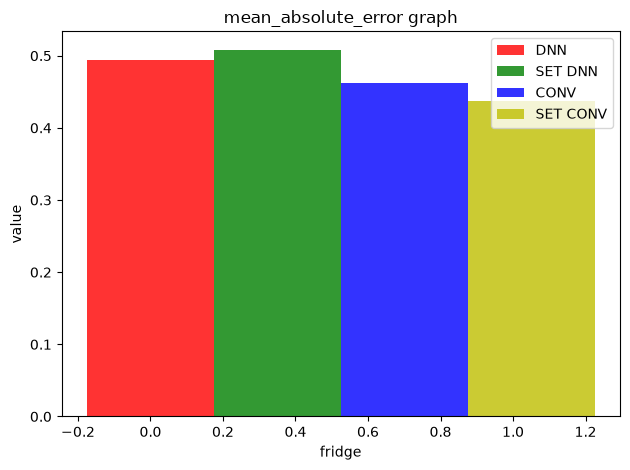

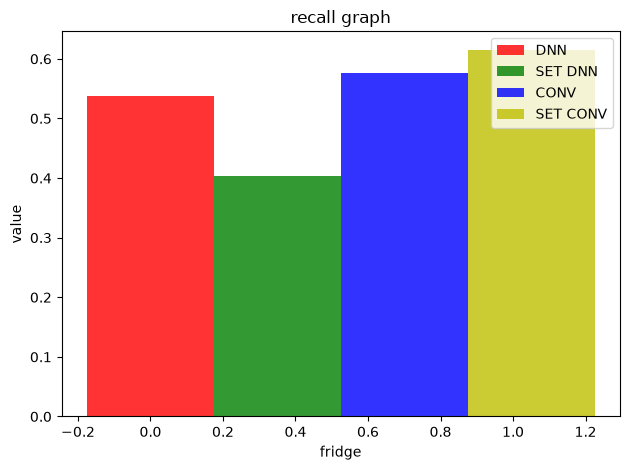

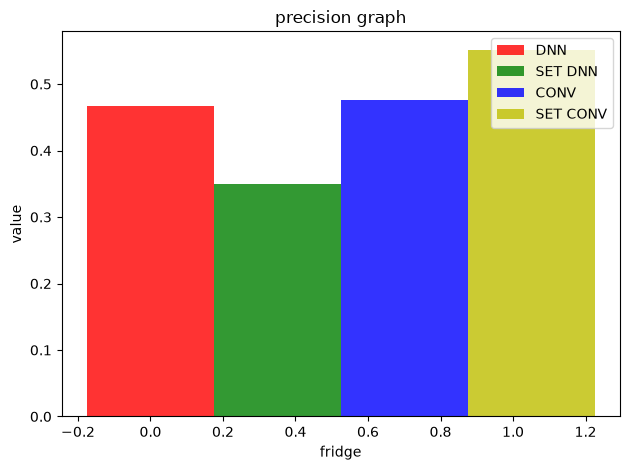

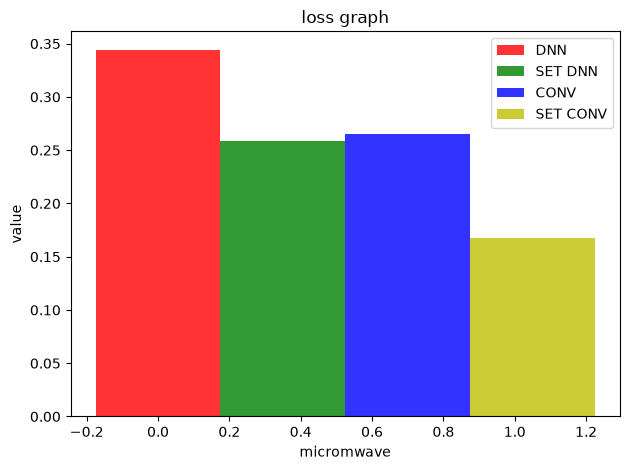

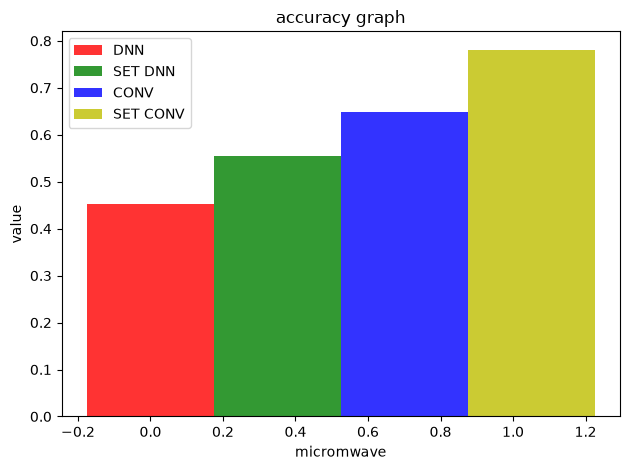

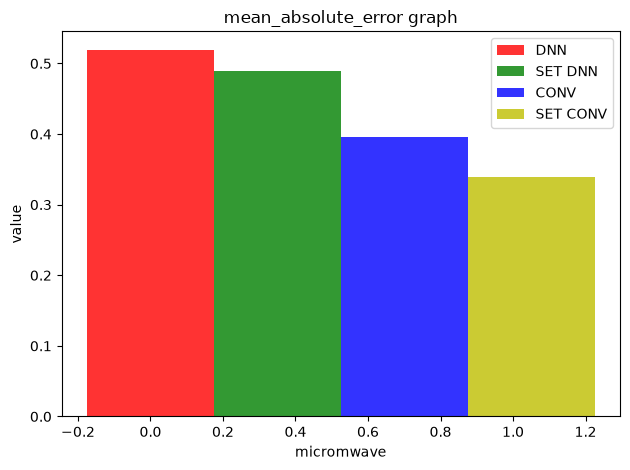

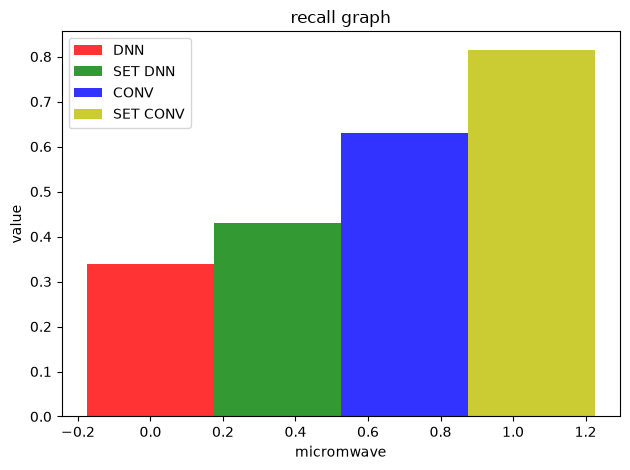

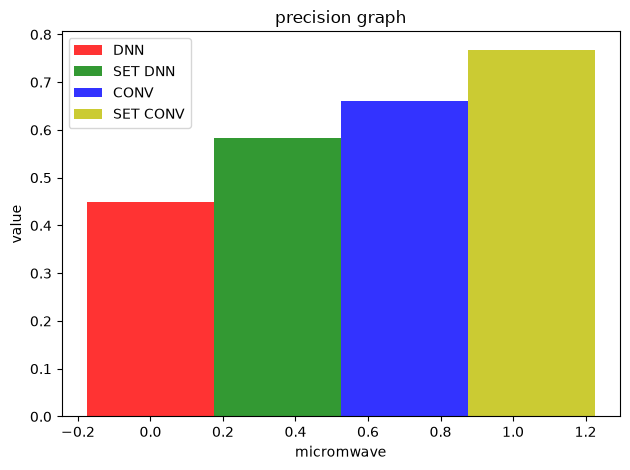

In [23]:
ms=['DNN','SET DNN','CONV','SET CONV']
device=['washing machine', 'dish washer', 'fridge', 'micromwave']
paras=['loss','accuracy','mean_absolute_error','recall','precision']
bar_width = 0.35
opacity = 0.8
for i in range(4):
  for j in range(5):

    index = np.arange(4)

    fig, ax = plt.subplots()

    rects1 = plt.bar(0, dh[i][paras[j]][-1], bar_width,
    alpha=opacity,
    color='red',
    label='DNN')

    rects2 = plt.bar(bar_width, sdh[i][paras[j]][-1], bar_width,
    alpha=opacity,
    color='g',
    label='SET DNN')

    rects3 = plt.bar(bar_width*2, ch[i][paras[j]][-1], bar_width,
    alpha=opacity,
    color='b',
    label='CONV')

    rects4 = plt.bar(bar_width*3, sch[i][paras[j]][-1], bar_width,
    alpha=opacity,
    color='y',
    label='SET CONV')

    plt.xlabel(device[i])
    plt.ylabel('value')
    plt.title(paras[j]+' graph')
    #plt.xticks(index + bar_width, ('washing machine', 'dish washer', 'fridage', 'micromwave'))
    plt.legend()

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / (device[i]+' '+paras[j]+' graph'+'.png'), dpi=150)
    plt.show(); plt.close()

In [24]:
for j in range(4):
  with open('SETCONVhis'+str(j), 'wb') as file_pi:
        pickle.dump(SETCONVhis[j], file_pi)


In [25]:
import pickle
for j in range(4):
  with open('DNNh'+str(j), 'wb') as file_pi:
        pickle.dump(DNNhis[j].history, file_pi)
  with open('SETDNNh'+str(j), 'wb') as file_pi:
        pickle.dump(SETDNNhis[j], file_pi)
  with open('CNNh'+str(j), 'wb') as file_pi:
        pickle.dump(CONVhis[j].history, file_pi)

In [26]:
import pickle
dh=[0]*4
sdh=[0]*4
ch=[0]*4
sch=[0]*4
for j in range(4):
  dh[j] = pickle.load(open('DNNh'+str(j), "rb"))
  sdh[j] = pickle.load(open('SETDNNh'+str(j), "rb"))
  ch[j] = pickle.load(open('CNNh'+str(j), "rb"))
  sch[j] = pickle.load(open('SETCONVhis'+str(j), "rb"))

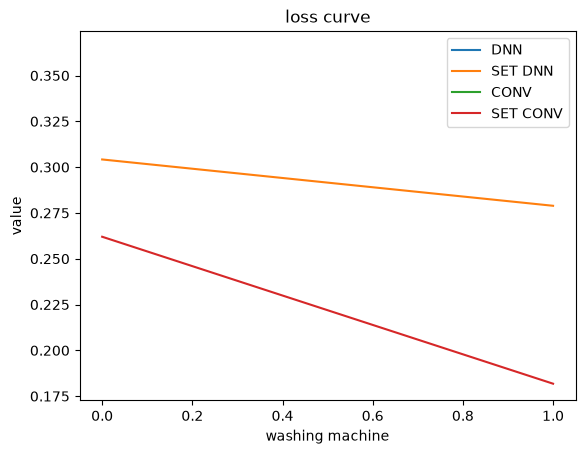

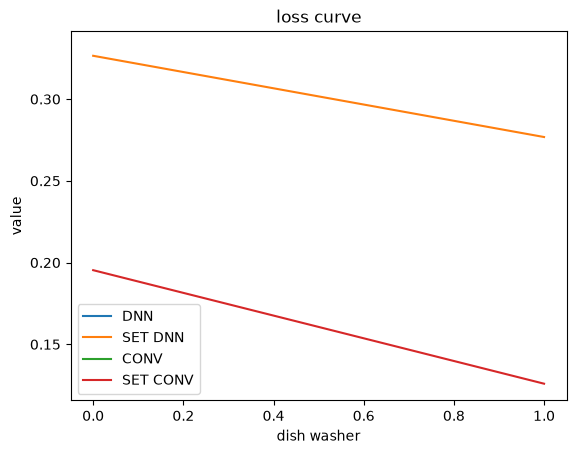

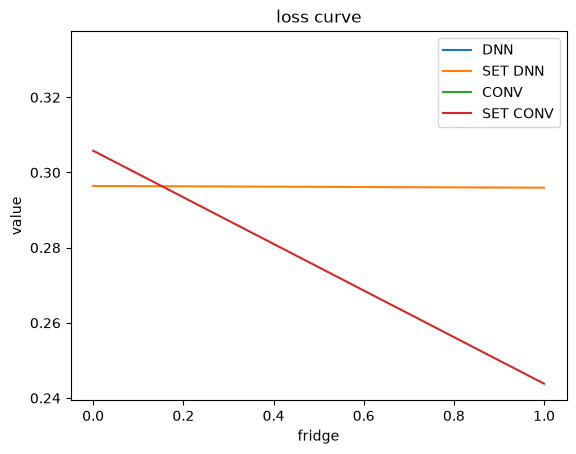

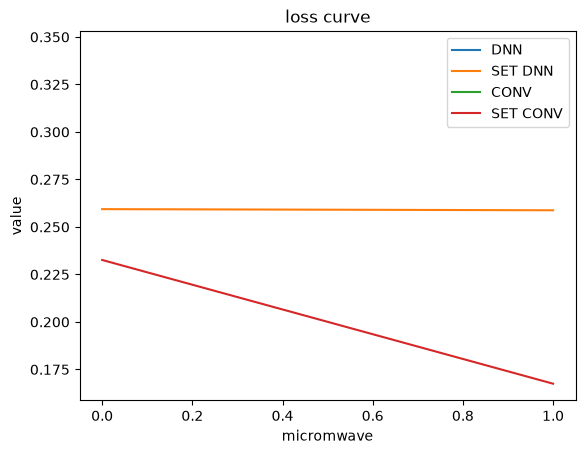

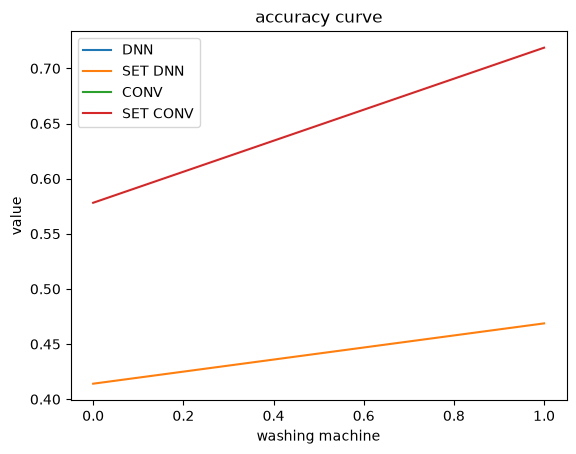

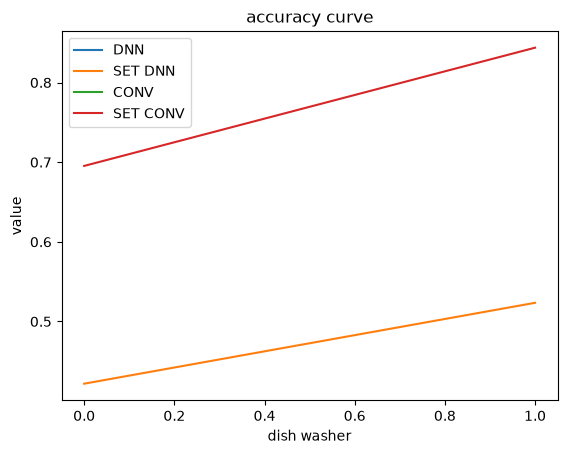

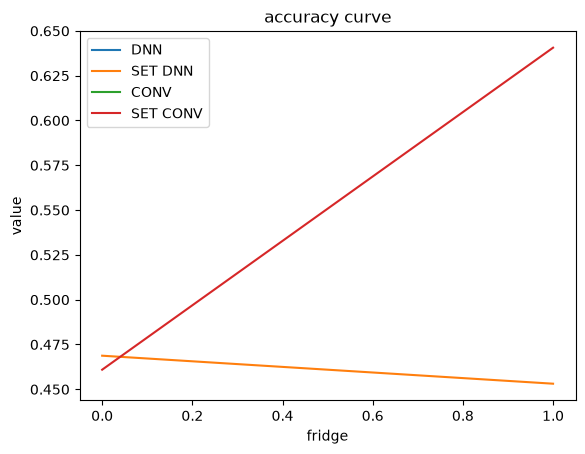

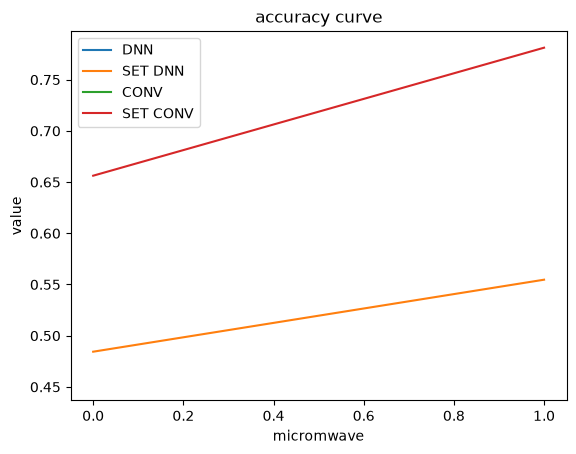

In [27]:
gn=['loss','accuracy']
device=['washing machine', 'dish washer', 'fridge', 'micromwave']

for i in range(2):
  for j in range(4):
    index=range(len(dh[j][gn[i]]))
    plt.plot(range(len(dh[j][gn[i]])),dh[j][gn[i]],label='DNN')
    plt.plot(range(len(sdh[j][gn[i]])),sdh[j][gn[i]], label='SET DNN')
    plt.plot(range(len(ch[j][gn[i]])),ch[j][gn[i]],label='CONV')
    plt.plot(range(len(sch[j][gn[i]])),sch[j][gn[i]],label='SET CONV')
    plt.xlabel(device[j])
    plt.ylabel('value')
    plt.title(gn[i]+' curve')
    plt.legend();
    plt.savefig(OUTPUT_DIR / (device[j]+' '+gn[i]+' curve'+'.png'), dpi=150)
    plt.show(); plt.close()

In [28]:
# Check finite training histories, held-out metrics, and sparse-mask enforcement.
import csv
families = {
    'DNN': (DNNmodel, [h.history for h in DNNhis]),
    'LASSO DNN': (DNNlasmodel, [h.history for h in DNNlashis]),
    'GROUP LASSO DNN': (DNNgrouplasmodel, [h.history for h in DNNgrouplashis]),
    'SET DNN': (SETDNNmodel, SETDNNhis),
    'CONV': (tmodel, [h.history for h in CONVhis]),
    'LASSO CONV': (tlasmodel, [h.history for h in CONVlashis]),
    'GROUP LASSO CONV': (cnngrouplasmodel, [h.history for h in CONVgrouplashis]),
    'SET CONV': (SETCONVmodel, SETCONVhis),
    'LASSO SET CONV': (SETLASSOCONVmodel, SETLASSOCONVhis),
}
rows = []
for family, (model_list, histories) in families.items():
    for target, (model, history) in enumerate(zip(model_list, histories)):
        assert all(np.isfinite(values).all() for values in history.values())
        scores = model.evaluate(testx, testylis[target], verbose=0, return_dict=True)
        assert all(np.isfinite(value) for value in scores.values())
        if 'SET' in family:
            layer = model.get_layer('dense_layer1')
            assert np.all(layer.get_weights()[0][layer.kernel_constraint.mask == 0] == 0)
        rows.append(dict(mode=RUN_MODE, family=family, target=target, **scores))
with open(OUTPUT_DIR / 'heldout_metrics.csv', 'w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
# Exercise rewiring and custom-object serialization independently.
_, sample_mask = createWeightsMask(2, 30, 10)
sample_weights = np.random.normal(size=sample_mask.shape).astype('float32') * sample_mask
new_mask, core = rewireMask(sample_weights, sample_mask.sum())
assert new_mask.sum() == sample_mask.sum()
assert np.all(core <= new_mask)
assert np.any(new_mask != sample_mask)
assert keras.regularizers.deserialize(keras.regularizers.serialize(L21(.001))).C == .001
print(f'Validated {len(rows)} model/target combinations in {RUN_MODE} mode.')


Validated 36 model/target combinations in smoke mode.
